In [3]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys
from pathlib import Path

scripts_path = str(Path.cwd().parents[0]) + "/scripts/"

if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

from Config import (
    CATALOGUE_JEROEN,
    POSITIONS_F115W,
    GAIA_CATALOGUE,
    MPLSTYLE,
    SB_PARAM_DIR,
    PHOT_DIR,
    PLOTS_DIR,
    LEVEL2_DIR,
    LEVEL3_DIR,
    STARBUG2_BIN,
)
import phot_toolkit as PTK
import photometric_pipeline as PPL
import plot_toolkit as PLOT
import Finding_accretor as FA


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from matplotlib.colors import to_rgb
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import astropy.units as u

if MPLSTYLE.exists():
    plt.style.use(str(MPLSTYLE))

working_directory = f"{LEVEL2_DIR}/mastDownload/JWST"
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory=working_directory)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black
/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts/


/net/vdesk/data2/slagter/environment_path/NGC_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']
Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


In [4]:
catalogue_path = "/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/Photometry/catalogue_jeroen/NGC346_NIRCam_and_MIRI_Public_JWST_Catalogue.fits"
Catalogue = PTK.Read_Catalogue(catalogue_path=catalogue_path)

In [5]:
Classifier = FA.Accretion_Finder(
    photometry_data=Catalogue.cat_data,
    max_mag_err=0.1,
    C1_name="F115W",
    C2_name="F187N",
    C3_name="F200W",
)

Classifier.Compute_rolling_median(window_size=1000)
Classifier.Select_CC_outliers(min_mag_diff=0.1, nsigma=3)

Found 286 out of 4668 excess sources


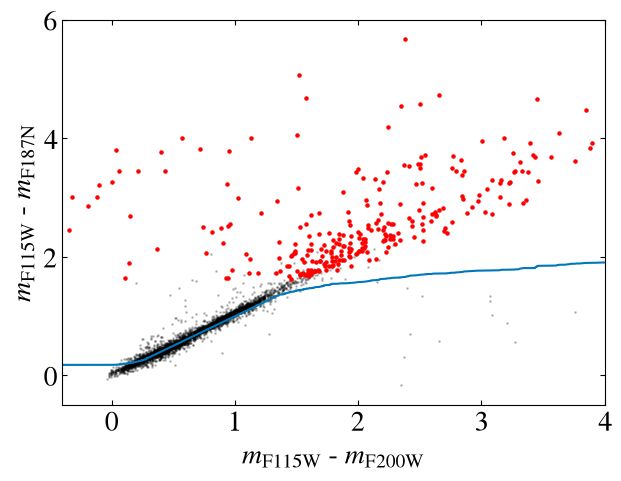

In [6]:
fig = plt.figure(figsize=(7, 5))
gs = gridspec.GridSpec(1, 1, figure=fig)
ax = fig.add_subplot(gs[0, 0])

ax.scatter(Classifier.C1_C3_color, Classifier.C1_C2_color, c="black", alpha=0.2, s=1)
ax.scatter(
    Classifier.C1_C3_color[Classifier.excess_mask],
    Classifier.C1_C2_color[Classifier.excess_mask],
    c="red",
    alpha=1,
    s=5,
)

ax.plot(Classifier.C1_C2_color, Classifier.rolling_median_C1_C2)

ax.set_xlabel(f"{PLOT._make_mag_name('F115W')} - {PLOT._make_mag_name('F200W')}")
ax.set_ylabel(f"{PLOT._make_mag_name('F115W')} - {PLOT._make_mag_name('F187N') }")

ax.set_xlim(-0.4, 4)
ax.set_ylim(-0.5, 6)
plt.show()